# **1. Perkenalan Dataset**


# 1. Perkenalan Dataset

Dataset yang digunakan dalam proyek ini adalah **Global Superyachts and Luxury Cruise Spatial Dataset** yang diperoleh dari Kaggle.

**Sumber Dataset:** https://www.kaggle.com/datasets/thinukakusalmith06/global-superyachts-and-luxury-cruise-spatial-dataset

Dataset ini berisi informasi mengenai kapal pesiar mewah, superyacht, dan berbagai jenis kapal lainnya. Informasi yang tersedia meliputi identitas kapal, klasifikasi kapal, produsen, tahun pembuatan, ukuran, spesifikasi mesin, kecepatan maksimum, dan kapasitas tamu.

Dataset ini digunakan untuk mempelajari karakteristik kapal serta melakukan analisis dan persiapan data sebelum pemodelan machine learning menggunakan algoritma K-Means untuk mengelompokkan kapal berdasarkan kemiripan karakteristik numeriknya.

## Informasi Kolom Dataset

| No. | Nama Kolom | Deskripsi |
|---|---|---|
| 1 | `Vessel_ID` | Identitas unik alfanumerik untuk setiap kapal. |
| 2 | `Vessel_Name` | Nama kapal pesiar atau yacht. |
| 3 | `Type` | Klasifikasi kapal, seperti Superyacht, Luxury Cruise, atau Expedition Yacht. |
| 4 | `Builder` | Produsen atau galangan kapal yang membangun kapal. |
| 5 | `Year_Built` | Tahun ketika kapal dibangun. |
| 6 | `Length_meters` | Panjang keseluruhan kapal dalam meter. |
| 7 | `Gross_Tonnage` | Ukuran volume internal kapal berdasarkan gross tonnage. |
| 8 | `Engine_Type` | Merek dan model mesin kapal yang digunakan. |
| 9 | `Top_Speed_knots` | Kecepatan maksimum kapal dalam satuan knot. |
| 10 | `Guests_Capacity` | Kapasitas maksimum tamu atau penumpang yang dapat ditampung kapal. |

## Tujuan Analisis

Analisis dilakukan untuk memahami karakteristik dataset, mengidentifikasi permasalahan kualitas data, dan menyiapkan fitur numerik yang sesuai untuk proses clustering. Hasil akhir preprocessing akan disimpan dalam file `preprocessed_data.csv`.

Tahapan yang dilakukan meliputi data loading, Exploratory Data Analysis (EDA), penanganan missing values, penghapusan data duplikat, pemeriksaan outlier, serta encoding fitur kategorikal jika diperlukan.


# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
# Library untuk pengolahan data
import pandas as pd
import numpy as np

# Library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk preprocessing
from sklearn.preprocessing import StandardScaler

# Library untuk mengelola file
from pathlib import Path

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [2]:
# Memuat dataset
df = pd.read_csv("/content/Global_Superyachts_and_Cruises.csv")


# Menampilkan lima baris pertama
display(df.head())

,Vessel_ID,Vessel_Name,Type,Builder,Year_Built,Length_meters,Gross_Tonnage,Engine_Type,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Current_Region,Latitude,Longitude
0,64ce98d3,Yacht_Wind_867,Luxury Cruise,Amels,2020,348.8,6368,MTU 20V 4000,26.9,1600,814,1149.30,Mediterranean Sea,34.637352,26.871785
1,53443fc0,Yacht_Wind_149,Superyacht,Oceanco,2021,57.5,1321,Volvo Penta,19.5,50,26,93.19,Persian Gulf,27.498674,52.560493
2,1f7d824d,Yacht_Star_447,Superyacht,Lürssen,2020,129.1,3550,Caterpillar 3516C,32.3,47,33,180.04,Persian Gulf,28.431264,51.035894
3,efda250c,Yacht_Wind_280,Superyacht,Heesen,2010,147.7,3392,Volvo Penta,27.5,39,26,232.14,Persian Gulf,24.425408,53.287280
4,f153e462,Yacht_Aqua_895,Superyacht,Blohm+Voss,2012,176.3,3248,Rolls-Royce Marine,30.7,34,22,223.96,Caribbean Sea,22.347593,-68.690359


In [3]:
# Memeriksa struktur dataset
df.info()

print("\nNama kolom:")
print(df.columns.tolist())

print("\nTipe data:")
display(df.dtypes.to_frame(name="Tipe Data"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Vessel_ID                     9000 non-null   object 
 1   Vessel_Name                   9000 non-null   object 
 2   Type                          9000 non-null   object 
 3   Builder                       9000 non-null   object 
 4   Year_Built                    9000 non-null   int64  
 5   Length_meters                 9000 non-null   float64
 6   Gross_Tonnage                 9000 non-null   int64  
 7   Engine_Type                   9000 non-null   object 
 8   Top_Speed_knots               9000 non-null   float64
 9   Guests_Capacity               9000 non-null   int64  
 10  Crew_Capacity                 9000 non-null   int64  
 11  Estimated_Value_USD_Millions  9000 non-null   float64
 12  Current_Region                9000 non-null   object 
 13  Lat

,Tipe Data
Vessel_ID,object
Vessel_Name,object
Type,object
Builder,object
Year_Built,int64
Length_meters,float64
Gross_Tonnage,int64
Engine_Type,object
Top_Speed_knots,float64
Guests_Capacity,int64


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

In [4]:
# Statistik deskriptif semua kolom
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Vessel_ID,9000,9000,51e4a4f8,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vessel_Name,9000,4388,Yacht_Sea_348,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,9000,4,Superyacht,5348,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Builder,9000,8,Lürssen,1168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year_Built,9000.0,NaN,NaN,NaN,2012.128667,7.228702,2000.0,2006.0,2012.0,2018.0,2024.0
Length_meters,9000.0,NaN,NaN,NaN,126.502289,64.982622,40.0,79.4,117.5,156.3,359.7
Gross_Tonnage,9000.0,NaN,NaN,NaN,2841.682667,1590.78544,623.0,1709.0,2530.0,3538.0,10679.0
Engine_Type,9000,5,Volvo Penta,1833,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Top_Speed_knots,9000.0,NaN,NaN,NaN,24.957589,5.749364,15.0,19.9,25.1,29.9,35.0
Guests_Capacity,9000.0,NaN,NaN,NaN,196.901444,558.262553,10.0,21.0,32.0,44.0,2999.0


In [5]:
# Menghitung missing values
missing_summary = pd.DataFrame({
    "Jumlah Missing": df.isnull().sum(),
    "Persentase Missing (%)": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

,Jumlah Missing,Persentase Missing (%)
Vessel_ID,0,0.0
Vessel_Name,0,0.0
Type,0,0.0
Builder,0,0.0
Year_Built,0,0.0
Length_meters,0,0.0
Gross_Tonnage,0,0.0
Engine_Type,0,0.0
Top_Speed_knots,0,0.0
Guests_Capacity,0,0.0


In [6]:
# Menghitung seluruh baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

# Memeriksa duplikasi berdasarkan ID jika tersedia
if "Vessel_ID" in df.columns:
    print(
        "Jumlah Vessel_ID duplikat:",
        df["Vessel_ID"].duplicated().sum()
    )

Jumlah baris duplikat: 0
Jumlah Vessel_ID duplikat: 0


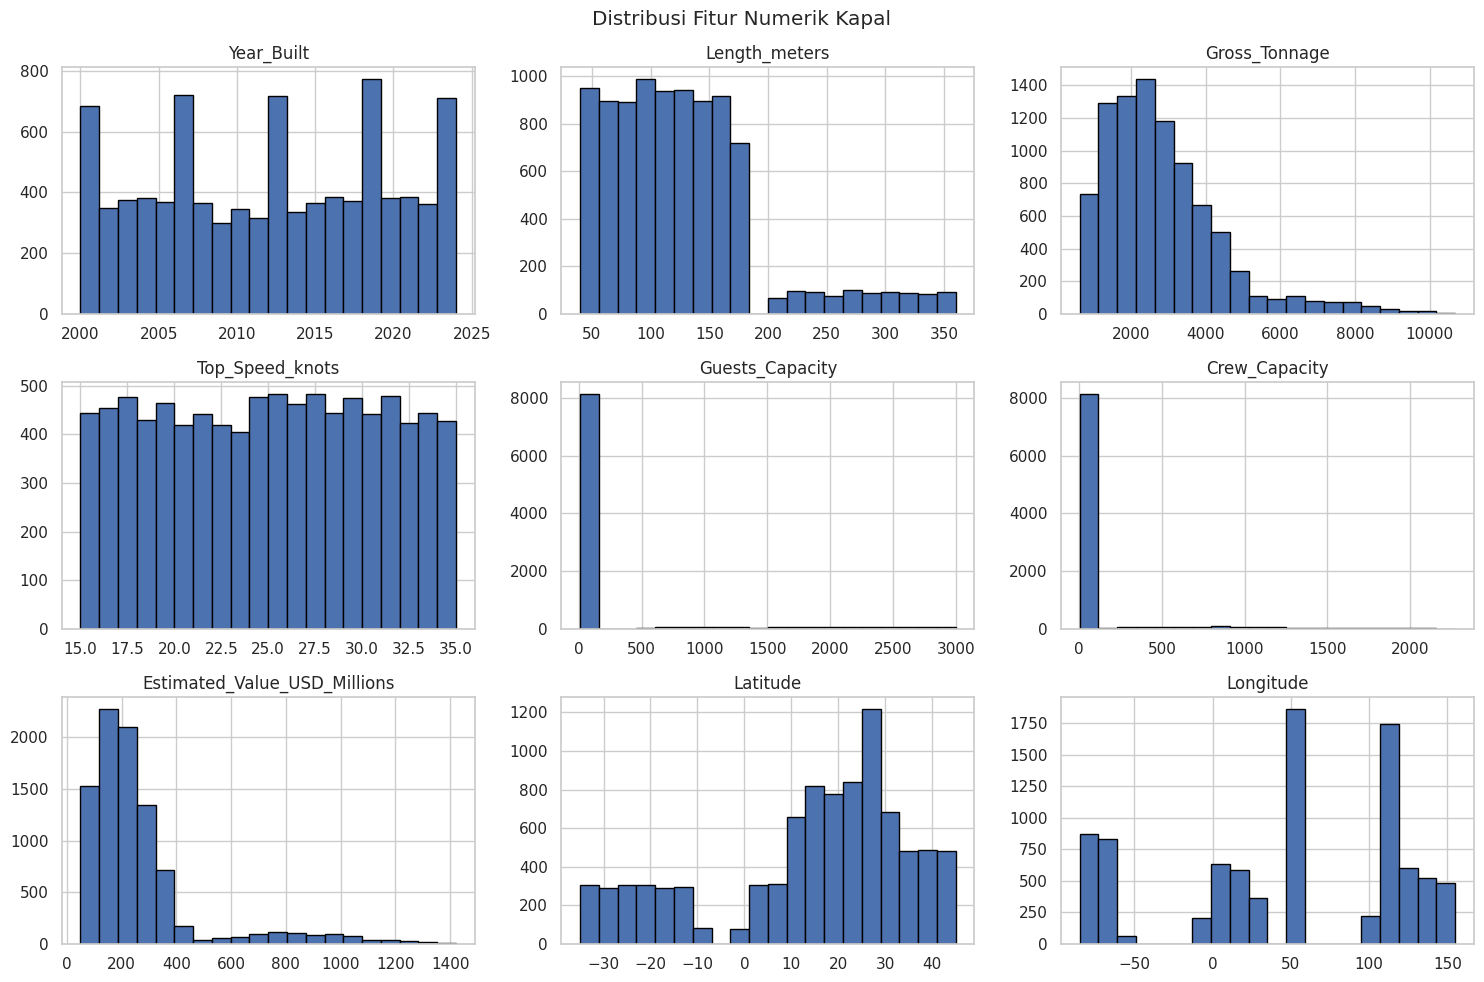

In [7]:
# Memilih kolom numerik
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

if numeric_columns:
    df[numeric_columns].hist(
        figsize=(15, 10),
        bins=20,
        edgecolor="black"
    )

    plt.suptitle("Distribusi Fitur Numerik Kapal")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan kolom numerik.")

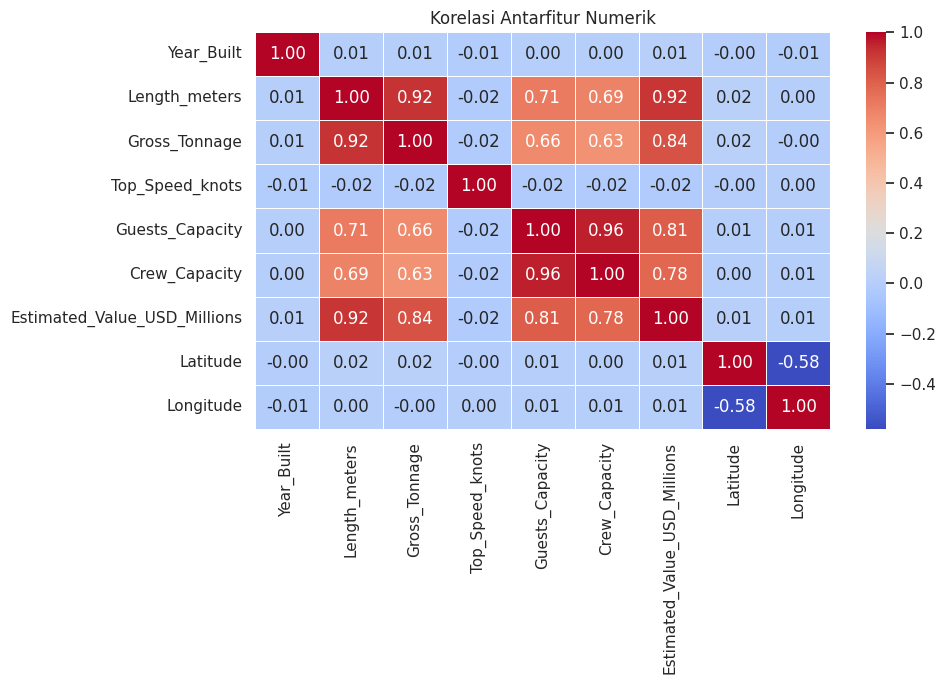

In [8]:
if len(numeric_columns) >= 2:
    plt.figure(figsize=(10, 7))

    sns.heatmap(
        df[numeric_columns].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Korelasi Antarfitur Numerik")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom numerik belum cukup untuk menghitung korelasi.")

Jumlah masing-masing jenis kapal:


,Jumlah Kapal
Type,
Superyacht,5348
Mega Yacht,1868
Expedition Yacht,915
Luxury Cruise,869


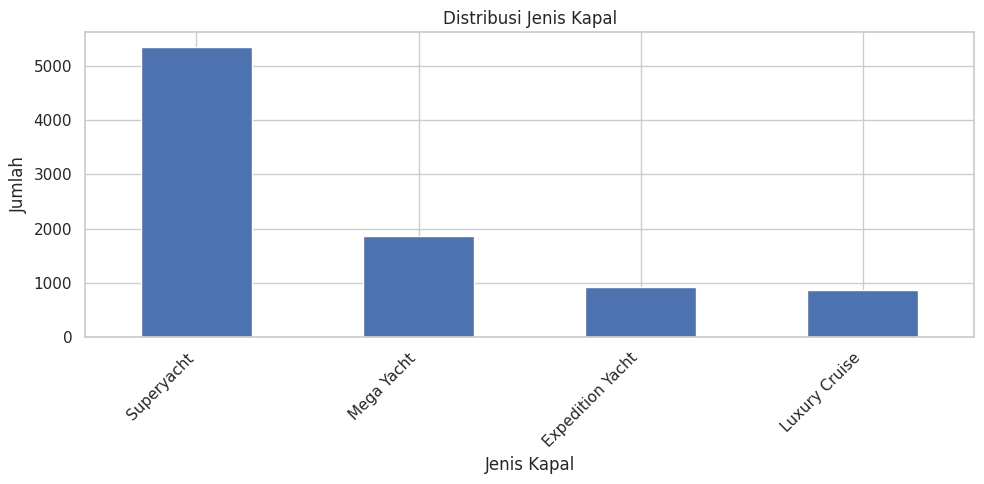

In [9]:
if "Type" in df.columns:
    print("Jumlah masing-masing jenis kapal:")
    display(df["Type"].value_counts(dropna=False).to_frame(
        name="Jumlah Kapal"
    ))

    df["Type"].value_counts().plot(
        kind="bar",
        figsize=(10, 5)
    )

    plt.title("Distribusi Jenis Kapal")
    plt.xlabel("Jenis Kapal")
    plt.ylabel("Jumlah")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

In [10]:
# Membuat salinan dataset
df_clean = df.copy()

# Menghapus spasi di awal dan akhir nama kolom
df_clean.columns = df_clean.columns.astype(str).str.strip()

# Menghapus kolom indeks yang tidak diperlukan
unnamed_columns = [
    col for col in df_clean.columns
    if col.lower().startswith("unnamed:")
]

df_clean.drop(
    columns=unnamed_columns,
    inplace=True
)

# Menghapus spasi pada nilai teks
for col in df_clean.select_dtypes(
    include=["object", "string"]
).columns:
    df_clean[col] = df_clean[col].map(
        lambda value: value.strip()
        if isinstance(value, str)
        else value
    )

# Mengubah nilai tak hingga menjadi missing values
df_clean.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

# Menghapus baris duplikat yang identik
df_clean.drop_duplicates(inplace=True)

print("Ukuran data asli:", df.shape)
print("Ukuran setelah pembersihan awal:", df_clean.shape)

display(df_clean.head())

Ukuran data asli: (9000, 15)
Ukuran setelah pembersihan awal: (9000, 15)


,Vessel_ID,Vessel_Name,Type,Builder,Year_Built,Length_meters,Gross_Tonnage,Engine_Type,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Current_Region,Latitude,Longitude
0,64ce98d3,Yacht_Wind_867,Luxury Cruise,Amels,2020,348.8,6368,MTU 20V 4000,26.9,1600,814,1149.30,Mediterranean Sea,34.637352,26.871785
1,53443fc0,Yacht_Wind_149,Superyacht,Oceanco,2021,57.5,1321,Volvo Penta,19.5,50,26,93.19,Persian Gulf,27.498674,52.560493
2,1f7d824d,Yacht_Star_447,Superyacht,Lürssen,2020,129.1,3550,Caterpillar 3516C,32.3,47,33,180.04,Persian Gulf,28.431264,51.035894
3,efda250c,Yacht_Wind_280,Superyacht,Heesen,2010,147.7,3392,Volvo Penta,27.5,39,26,232.14,Persian Gulf,24.425408,53.287280
4,f153e462,Yacht_Aqua_895,Superyacht,Blohm+Voss,2012,176.3,3248,Rolls-Royce Marine,30.7,34,22,223.96,Caribbean Sea,22.347593,-68.690359


In [11]:
# Fitur yang akan digunakan untuk clustering
features = [
    "Year_Built",
    "Length_meters",
    "Gross_Tonnage",
    "Top_Speed_knots",
    "Guests_Capacity"
]

missing_columns = [
    col for col in features
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Kolom berikut tidak ditemukan dalam dataset: {missing_columns}. "
        "Periksa nama kolom pada file CSV asli."
    )

print("Semua fitur utama tersedia.")

Semua fitur utama tersedia.


In [12]:
# Mengonversi fitur menjadi tipe numerik
for col in features:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

# Mengubah nilai tak hingga menjadi NaN
df_clean[features] = df_clean[features].replace(
    [np.inf, -np.inf],
    np.nan
)

# Menghitung missing values setelah konversi
display(
    df_clean[features].isnull().sum().to_frame(
        name="Jumlah Missing"
    )
)

,Jumlah Missing
Year_Built,0
Length_meters,0
Gross_Tonnage,0
Top_Speed_knots,0
Guests_Capacity,0


In [13]:
# Menghapus baris jika seluruh fitur utama kosong
df_clean.dropna(
    subset=features,
    how="all",
    inplace=True
)

# Mengisi missing values pada fitur numerik dengan median
for col in features:
    if df_clean[col].isnull().any():
        median_value = df_clean[col].median()

        if pd.notna(median_value):
            df_clean[col] = df_clean[col].fillna(
                median_value
            )

# Mengisi missing values kolom lainnya
for col in df_clean.columns:
    if col in features:
        continue

    if df_clean[col].isnull().any():
        if (
            pd.api.types.is_numeric_dtype(df_clean[col])
            and df_clean[col].notna().any()
        ):
            df_clean[col] = df_clean[col].fillna(
                df_clean[col].median()
            )
        else:
            mode_values = df_clean[col].mode(dropna=True)

            if not mode_values.empty:
                df_clean[col] = df_clean[col].fillna(
                    mode_values.iloc[0]
                )

print(
    "Missing values pada fitur utama:",
    df_clean[features].isnull().sum().sum()
)

Missing values pada fitur utama: 0


In [14]:
# Memeriksa outlier menggunakan metode IQR
outlier_summary = []

for col in features:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df_clean[col] < lower_bound)
        | (df_clean[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Kolom": col,
        "Batas Bawah": lower_bound,
        "Batas Atas": upper_bound,
        "Jumlah Outlier": int(outlier_count)
    })

display(pd.DataFrame(outlier_summary))

,Kolom,Batas Bawah,Batas Atas,Jumlah Outlier
0,Year_Built,1988.00,2036.00,0
1,Length_meters,-35.95,271.65,500
2,Gross_Tonnage,-1034.50,6281.50,431
3,Top_Speed_knots,4.90,44.90,0
4,Guests_Capacity,-13.50,78.50,869


In [15]:
# Memastikan fitur utama tidak memiliki missing values
assert df_clean[features].notnull().all().all(), (
    "Masih terdapat missing values pada fitur utama."
)

# Memastikan fitur utama bersifat numerik
assert all(
    pd.api.types.is_numeric_dtype(df_clean[col])
    for col in features
), "Masih terdapat fitur utama yang bukan numerik."

# Menyimpan dataset hasil preprocessing
output_path = Path("preprocessed_data.csv")

df_clean.to_csv(
    output_path,
    index=False
)

print("Preprocessing selesai.")
print("Jumlah baris akhir:", df_clean.shape[0])
print("Jumlah kolom akhir:", df_clean.shape[1])
print("File tersimpan:", output_path)

display(df_clean.head())

Preprocessing selesai.
Jumlah baris akhir: 9000
Jumlah kolom akhir: 15
File tersimpan: preprocessed_data.csv


,Vessel_ID,Vessel_Name,Type,Builder,Year_Built,Length_meters,Gross_Tonnage,Engine_Type,Top_Speed_knots,Guests_Capacity,Crew_Capacity,Estimated_Value_USD_Millions,Current_Region,Latitude,Longitude
0,64ce98d3,Yacht_Wind_867,Luxury Cruise,Amels,2020,348.8,6368,MTU 20V 4000,26.9,1600,814,1149.30,Mediterranean Sea,34.637352,26.871785
1,53443fc0,Yacht_Wind_149,Superyacht,Oceanco,2021,57.5,1321,Volvo Penta,19.5,50,26,93.19,Persian Gulf,27.498674,52.560493
2,1f7d824d,Yacht_Star_447,Superyacht,Lürssen,2020,129.1,3550,Caterpillar 3516C,32.3,47,33,180.04,Persian Gulf,28.431264,51.035894
3,efda250c,Yacht_Wind_280,Superyacht,Heesen,2010,147.7,3392,Volvo Penta,27.5,39,26,232.14,Persian Gulf,24.425408,53.287280
4,f153e462,Yacht_Aqua_895,Superyacht,Blohm+Voss,2012,176.3,3248,Rolls-Royce Marine,30.7,34,22,223.96,Caribbean Sea,22.347593,-68.690359
